# Interventions: three experiments on GPT-2 and IOI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/notebooks/03_interventions.ipynb)

spectral-trust 0.5.0 adds `st.intervene`, which edits a Hugging Face model
with hooks and undoes every edit on exit, and `st.Patcher`, which patches
activations, plain or one graph-frequency band at a time. This notebook runs
three of the [use cases](https://vcnoel.github.io/spectral-trust/use-cases/)
on GPT-2 small and the indirect-object identification (IOI) task, each
against a control that could produce the same result: (a) removing attention
edges with three ways of handling the removed mass, (b) low-pass and
high-pass graph filters of the residual stream against the same filters on a
random graph, matched in edit size, and (c) patching one band of graph
frequencies. Every number below is computed in this notebook, on the same 200
IOI prompts as the use-case pages.

**Runtime:** CPU (Colab: *Runtime > Change runtime type > CPU*). The first
run downloads GPT-2 small (about 550 MB), the official IOI dataset code and
the WikiText-2 test split; the three experiments then take about five to ten
minutes on Colab's two CPU cores.

In [1]:
%pip install -q "spectral-trust[viz]==0.5.0" datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault("TQDM_DISABLE", "1")          # no progress bars in the outputs

import numpy as np
import torch
import transformers

import spectral_trust as st

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
print("spectral-trust", st.__version__, "| torch", torch.__version__,
      "| transformers", transformers.__version__)

torch.set_grad_enabled(False)

spectral-trust 0.5.0 | torch 2.11.0+cu128 | transformers 5.2.0


torch.autograd.grad_mode.set_grad_enabled(mode=False)

## IOI prompts and the model

The prompts come from the dataset code of Wang et al. (2022), downloaded from
the authors' repository at a fixed commit and checked against its SHA-256.
With the seeds below, `ioi_pairs()` gives the 200 prompts of the use-case
pages (100 ABBA and 100 BABA), each with a corrupted counterpart whose three
names are replaced by random names. The metric is the logit difference
LD = logit(IO) − logit(S) at the END position, the token before the answer.

In [3]:
import hashlib
import random
import sys
import urllib.request

IOI_URL = ("https://raw.githubusercontent.com/redwoodresearch/Easy-Transformer/"
           "e168301aa05154a14d52e5b6f98b6518200f5b1f/easy_transformer/ioi_dataset.py")
IOI_SHA256 = "94a72de90e426382322fd690669024a0d2d4bd72a45ed9ce820a99ae9173d231"
if not os.path.exists("ioi_dataset.py"):
    urllib.request.urlretrieve(IOI_URL, "ioi_dataset.py")
with open("ioi_dataset.py", "rb") as f:
    assert hashlib.sha256(f.read()).hexdigest() == IOI_SHA256, "unexpected ioi_dataset.py"
sys.path.insert(0, os.getcwd())
from ioi_dataset import IOIDataset


def ioi_pairs(n_per_template=100, seed=0):
    """The IOI prompts cropped to [0, END], with their ABC counterparts
    (as in examples/use_cases/_common.py)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    parts = [IOIDataset(prompt_type=t, N=n_per_template, prepend_bos=False)
             for t in ("ABBA", "BABA")]
    flipped = [ds.gen_flipped_prompts(("IO", "RAND")).gen_flipped_prompts(("S", "RAND"))
               .gen_flipped_prompts(("S1", "RAND")) for ds in parts]
    pairs = []
    for ds, fl in zip(parts, flipped):
        ends, fends = ds.word_idx["end"], fl.word_idx["end"]
        for i in range(ds.N):
            e = int(ends[i])
            toks, ftoks = ds.toks[i].long(), fl.toks[i].long()
            clean, corrupt = toks[: e + 1].clone(), ftoks[: e + 1].clone()
            pos = {k: int(ds.word_idx[k][i]) for k in ("IO", "S", "S2")}
            diff = set(torch.nonzero(clean != corrupt).flatten().tolist())
            if int(fends[i]) != e or not diff <= set(pos.values()):
                continue
            pairs.append(dict(text=ds.sentences[i], clean=clean, corrupt=corrupt, end=e,
                              io=int(ds.io_tokenIDs[i]), s=int(ds.s_tokenIDs[i]),
                              pos_io=pos["IO"], pos_s1=pos["S"], pos_s2=pos["S2"]))
    return pairs


pairs = ioi_pairs()
groups = {}                                   # prompts grouped by length: no padding
for i, p in enumerate(pairs):
    groups.setdefault(len(p["clean"]), []).append(i)
IO = torch.tensor([p["io"] for p in pairs])
S = torch.tensor([p["s"] for p in pairs])
print(len(pairs), "prompts, lengths", sorted(groups))
print(pairs[0]["text"])

200 prompts, lengths [14, 15, 16, 17, 18, 19, 20]
The store Crystal and Bradley went to had a computer. Bradley gave it to Crystal


In [4]:
model = st.SpectralModel.from_pretrained("gpt2")
hf = model.model.eval()


def logit_diff(edit=None, which="clean"):
    """LD per prompt; ``edit(iv, idx, T)`` registers edits on one length group."""
    out = np.zeros(len(pairs))
    for T, idx in groups.items():
        ids = torch.stack([pairs[i][which] for i in idx])
        if edit is None:
            logits = hf(input_ids=ids, logits_to_keep=1).logits[:, -1]
        else:
            with st.intervene(hf) as iv:
                edit(iv, idx, T)
                logits = hf(input_ids=ids, logits_to_keep=1).logits[:, -1]
        r, ii = torch.arange(len(idx)), torch.as_tensor(idx)
        out[idx] = (logits[r, IO[ii]] - logits[r, S[ii]]).numpy()
    return out


BOOT = np.random.default_rng(0).integers(0, len(pairs), size=(10_000, len(pairs)))


def ci(x, idx=BOOT):
    """Mean and 95% percentile bootstrap interval over items."""
    bs = np.asarray(x)[idx].mean(1)
    return float(np.mean(x)), float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))


def fmt(c, d=2):
    return f"{c[0]:+.{d}f} [{c[1]:+.{d}f}, {c[2]:+.{d}f}]"


ld_clean = logit_diff()
print("clean LD", fmt(ci(ld_clean)), f"| positive on {np.mean(ld_clean > 0):.0%} of prompts")

clean LD +3.64 [+3.43, +3.85] | positive on 100% of prompts


## (a) Removing attention edges: where does the mass go?

Once an attention entry is set to zero, its row no longer sums to one, and
something must happen to the missing mass. `remove_edges` makes the choice an
argument:

- `keep_sink=True` (the default): the first token, the attention sink, keeps
  its value, and the removed mass goes to the other keys in proportion to
  their attention;
- `keep_sink=False`: the row is renormalised over every remaining key, the
  sink included, which is what a pattern hook that divides by the row sum does;
- `renormalize=False`: the entries are zeroed and the row sums to less than one.

The experiment removes the edges from END to the three name tokens (IO, S1,
S2) in the name-mover heads 9.6, 9.9 and 10.0 together, and in random triples
of other heads (seed 0) as a control, under each choice
([use-case page](https://vcnoel.github.io/spectral-trust/use-cases/sink-ablation/)).

In [5]:
NAME_MOVERS = [(9, 6), (9, 9), (10, 0)]
CHOICES = {"keep_sink=True": dict(keep_sink=True),
           "keep_sink=False": dict(keep_sink=False),
           "renormalize=False": dict(keep_sink=True, renormalize=False)}
N_RANDOM = 10                                  # random head triples (the page uses 20)


def remove_names(heads, choice):
    def edit(iv, idx, T):
        mask = torch.zeros(len(idx), T, T, dtype=torch.bool)
        for j, i in enumerate(idx):
            p = pairs[i]
            mask[j, p["end"], [p["pos_io"], p["pos_s1"], p["pos_s2"]]] = True
        by_layer = {}
        for layer, head in heads:
            by_layer.setdefault(layer, []).append(head)
        for layer, hs in by_layer.items():
            iv.attention(layer, hs).remove_edges(mask, **CHOICES[choice])
    return edit


pool = [(l, h) for l in range(12) for h in range(12) if (l, h) not in NAME_MOVERS]
rng = np.random.default_rng(0)
random_sets = [sorted(pool[i] for i in rng.choice(len(pool), size=3, replace=False))
               for _ in range(20)][:N_RANDOM]

effect = {}
for choice in CHOICES:
    effect["name movers", choice] = logit_diff(remove_names(NAME_MOVERS, choice)) - ld_clean
    effect["random triples", choice] = np.mean(
        [logit_diff(remove_names(hs, choice)) - ld_clean for hs in random_sets], axis=0)

`remove_edges` warns when holding the sink fixed multiplies the kept edges of
a row by more than 10, as it does in the name movers. The attention mass the
removed edges carried, and the change in LD, with 95% bootstrap intervals over
the 200 prompts:

In [6]:
att = {}                                       # clean attention at END: names, sink, other keys
for T, idx in groups.items():
    ids = torch.stack([pairs[i]["clean"] for i in idx])
    A = torch.stack(hf(input_ids=ids, output_attentions=True).attentions, 1)   # [B, L, H, T, T]
    for j, i in enumerate(idx):
        p = pairs[i]
        row = A[j, :, :, p["end"]]                                             # [L, H, T]
        names = row[..., [p["pos_io"], p["pos_s1"], p["pos_s2"]]].sum(-1)
        att[i] = torch.stack([names, row[..., 0]], -1).numpy()                 # [L, H, 2]
mass = np.stack([att[i] for i in range(len(pairs))])                          # [prompts, L, H, 2]
m_nm = np.mean([mass[:, l, h, 0] for l, h in NAME_MOVERS], 0)
m_rs = np.mean([np.mean([mass[:, l, h, 0] for l, h in hs], 0) for hs in random_sets], 0)
print(f"removed mass: name movers {m_nm.mean():.2f}, random triples {m_rs.mean():.2f}\n")
print(f"{'heads':16s}{'choice':20s}{'change in LD':>24s}")
for (heads, choice), x in effect.items():
    print(f"{heads:16s}{choice:20s}{fmt(ci(x)):>24s}")

removed mass: name movers 0.77, random triples 0.15

heads           choice                          change in LD
name movers     keep_sink=True          -0.79 [-0.90, -0.68]
random triples  keep_sink=True          -0.15 [-0.16, -0.13]
name movers     keep_sink=False         -0.12 [-0.23, -0.01]
random triples  keep_sink=False         -0.14 [-0.15, -0.13]
name movers     renormalize=False       +0.08 [-0.03, +0.18]
random triples  renormalize=False       -0.13 [-0.15, -0.12]


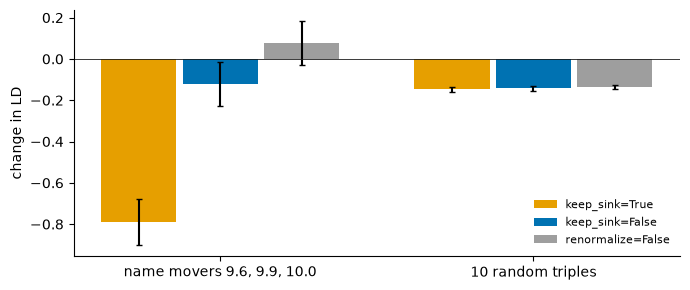

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3))
colors = {"keep_sink=True": "#E69F00", "keep_sink=False": "#0072B2", "renormalize=False": "#9E9E9E"}
for k, heads in enumerate(["name movers", "random triples"]):
    for j, choice in enumerate(CHOICES):
        m, lo, hi = ci(effect[heads, choice])
        ax.bar(k + (j - 1) * 0.26, m, 0.24, yerr=[[m - lo], [hi - m]], color=colors[choice],
               label=choice if k == 0 else None, capsize=2)
ax.axhline(0, color="#1A1A1A", lw=0.6)
ax.set_xticks([0, 1], ["name movers 9.6, 9.9, 10.0", f"{N_RANDOM} random triples"])
ax.set_ylabel("change in LD")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**The same edges, three conclusions.** With the sink held fixed, the name
movers' edges to the names carry about a fifth of the clean logit difference;
with plain renormalisation, a small share; with zeroing, none. In the random
triples the removed edges carry little of the row, and the three choices
agree. The composition of the name movers' END rows shows why:

In [8]:
s_nm = np.mean([mass[:, l, h, 1] for l, h in NAME_MOVERS], 0)      # sink share, per prompt
names, sink = m_nm, s_nm
other = 1 - names - sink
rows = {"clean": (names.mean(), sink.mean(), other.mean()),
        "keep_sink=True": (0, sink.mean(), (1 - sink).mean()),
        "keep_sink=False": (0, (sink / (1 - names)).mean(), (other / (1 - names)).mean()),
        "renormalize=False": (0, sink.mean(), other.mean())}
print(f"{'END row of the name movers':28s}{'names':>8s}{'sink':>8s}{'other':>8s}{'sum':>8s}")
for k, (a, s_, o) in rows.items():
    print(f"{k:28s}{a:8.2f}{s_:8.2f}{o:8.2f}{a + s_ + o:8.2f}")

END row of the name movers     names    sink   other     sum
clean                           0.77    0.20    0.03    1.00
keep_sink=True                  0.00    0.20    0.80    1.00
keep_sink=False                 0.00    0.86    0.14    1.00
renormalize=False               0.00    0.20    0.03    0.23


Holding the sink fixed gives the removed mass to the few content keys left,
whose attention is multiplied many times; plain renormalisation gives most of
it to the sink; zeroing gives it to no key and shrinks the head's output. None
of the three is neutral when the removed edges hold most of the row: report
the removed mass with any edge ablation, and when it is large, run all three.

## (b) Graph-frequency steering against a random graph of the same size

`graph_filter` filters the residual stream along the token axis in the
frequency basis of the layer's attention graph, `X' = X + s (g(L) X − X)`. A
low-pass filter smooths each position towards the tokens it is linked to; a
high-pass filter keeps what distinguishes a token from its neighbours. Here
the filters act after block 5, with `causal=True` (each position is filtered
on the graph of its own prefix, so no position reads a later token) and
`token_span=(1, None)` (the first token, whose residual norm in GPT-2 dwarfs
the others', is left out).

The control applies the same filter on a random graph: each query row's
attention weights permuted among the keys of its prefix (the row keeps its
weights, not which tokens get them), rescaled per prompt to the same edit
norm. A difference between the two is due to which tokens the attention graph
links, not to the size of the edit. The effect is the change in IOI LD; the
side effect, the change in next-token loss on 200 WikiText-2 test passages of
32 tokens ([use-case page](https://vcnoel.github.io/spectral-trust/use-cases/graph-filter-steering/)).

In [9]:
from datasets import load_dataset

LAYER, CUTOFF = 5, 1.0
CONDITIONS = [("lowpass", 1.0), ("highpass", 0.25)]

wiki = []
for line in load_dataset("wikitext", "wikitext-2-raw-v1", split="test")["text"]:
    line = line.strip()
    if line and not line.startswith("="):
        ids = model.tokenizer(line)["input_ids"]
        if len(ids) >= 32:
            wiki.append(ids[:32])
    if len(wiki) == 200:
        break
wiki = torch.tensor(wiki)

gc = st.GraphConstructor(model.config)


def shuffled_graph(P):
    """A random-graph callable for st.graph_filter: each query row's weights
    permuted among the keys of its prefix (``P`` from shuffle_index)."""
    def graph(att, x):
        m = att.shape[-1]
        idx = P[:, :m, :m].unsqueeze(1).expand(-1, att.shape[1], -1, -1)
        return gc.aggregate_heads(gc.symmetrize_attention(att.double().gather(-1, idx)))
    return graph


def shuffle_index(seeds, n):
    P = torch.arange(n).repeat(len(seeds), n, 1)
    for b_, seed in enumerate(seeds):
        r = np.random.default_rng([1, int(seed)])
        for q in range(1, n):
            P[b_, q, : q + 1] = torch.from_numpy(r.permutation(q + 1))
    return P


# batches: IOI prompts by length, and WikiText passages by 50
batches = [("ioi", torch.stack([pairs[i]["clean"] for i in idx]), idx, idx)
           for idx in groups.values()]
batches += [("wiki", wiki[a:a + 50], list(range(a, a + 50)), [10_000 + i for i in range(a, a + 50)])
            for a in range(0, len(wiki), 50)]

# the edit of every condition, from the unedited run (block 5's input is unchanged by it)
deltas = {}                                    # (kind, strength, graph) -> list of [B, T-1, d]
size = {}
for kind_, ids, idx, seeds in batches:
    out = hf(input_ids=ids, output_attentions=True, output_hidden_states=True)
    xs = out.hidden_states[LAYER + 1][:, 1:].double()               # block 5 output, tokens 1..
    As = out.attentions[LAYER][:, :, 1:, 1:]
    xn = xs.flatten(1).norm(dim=1)
    for kind, s in CONDITIONS:
        d_att = st.graph_filter(xs, As, kind=kind, cutoff=CUTOFF, causal=True) - xs
        d_rnd = st.graph_filter(xs, As, kind=kind, cutoff=CUTOFF, causal=True,
                                graph=shuffled_graph(shuffle_index(seeds, xs.shape[1]))) - xs
        na = d_att.flatten(1).norm(dim=1)
        k_rnd = na / d_rnd.flatten(1).norm(dim=1).clamp_min(1e-12)    # norm matching
        deltas.setdefault((kind, s, "attention"), []).append(s * d_att)
        deltas.setdefault((kind, s, "random graph"), []).append(s * k_rnd.view(-1, 1, 1) * d_rnd)
        if kind_ == "wiki":
            size.setdefault((kind, s), []).extend((s * na / xn).tolist())

In [10]:
def evaluate(key=None):
    """(LD per IOI prompt, next-token loss per passage) with one precomputed edit."""
    ld, nll = np.zeros(len(pairs)), np.zeros(len(wiki))
    for b_, (kind_, ids, idx, _) in enumerate(batches):
        def add(x, d=None if key is None else deltas[key][b_]):
            y = x.clone()
            y[:, 1:] += d.to(x.dtype)
            return y
        with st.intervene(hf) as iv:
            if key is not None:
                iv.hook("resid_post", LAYER, add)
            logits = hf(input_ids=ids).logits
        if kind_ == "ioi":
            r, ii = torch.arange(len(idx)), torch.as_tensor(idx)
            ld[idx] = (logits[r, -1, IO[ii]] - logits[r, -1, S[ii]]).numpy()
        else:
            lp = logits[:, :-1].log_softmax(-1)
            nll[idx] = -lp.gather(-1, ids[:, 1:, None])[..., 0].mean(-1).numpy()
    return ld, nll


ld0, nll0 = evaluate()
BOOT_W = np.random.default_rng(1).integers(0, len(wiki), size=(10_000, len(wiki)))
print(f"unedited: LD {ld0.mean():.2f}, next-token loss {nll0.mean():.2f} nats\n")
print(f"{'edit after block 5':30s}{'size':>6s}{'change in LD':>24s}{'change in loss (nats)':>26s}")
results = {}
for kind, s in CONDITIONS:
    for graph in ("attention", "random graph"):
        ld, nll = evaluate((kind, s, graph))
        results[kind, s, graph] = (ld - ld0, nll - nll0)
        print(f"{f'{kind} s={s}, {graph}':30s}{np.mean(size[kind, s]):6.2f}"
              f"{fmt(ci(ld - ld0)):>24s}{fmt(ci(nll - nll0, BOOT_W)):>26s}")

unedited: LD 3.64, next-token loss 4.80 nats

edit after block 5              size            change in LD     change in loss (nats)


lowpass s=1.0, attention        0.28    -3.21 [-3.62, -2.80]      +0.30 [+0.28, +0.33]


lowpass s=1.0, random graph     0.28    -2.48 [-2.77, -2.19]      +0.17 [+0.15, +0.20]


highpass s=0.25, attention      0.23    +0.40 [+0.31, +0.49]      +0.04 [+0.03, +0.05]


highpass s=0.25, random graph   0.23    +0.23 [+0.14, +0.34]      +0.04 [+0.03, +0.05]


"size" is the relative edit `‖X' − X‖ / ‖X‖` on the WikiText passages, the
same for both graphs by construction. The library edit computes the same
thing in one line; the check below compares it with the precomputed
attention-graph edit:

In [11]:
def library_edit(iv, idx, T):
    iv.resid(LAYER).graph_filter("lowpass", cutoff=CUTOFF, strength=1.0,
                                 causal=True, token_span=(1, None))

ld_lib = logit_diff(library_edit)
ld_pre = results["lowpass", 1.0, "attention"][0] + ld0
print(f"library edit against the precomputed one: max |difference in LD| = "
      f"{np.abs(ld_lib - ld_pre).max():.1e}")

library edit against the precomputed one: max |difference in LD| = 8.4e-05


Both graphs move LD in the same direction: most of the effect follows the size
of the edit. The side effect is where the attention graph differs. Smoothing
along it costs more next-token loss than smoothing of the same size along the
random graph, and removing its low frequencies costs about as much or less.

**Generation.** Greedy continuations with the library edit at increasing
strength, each recomputing the sequence at every step as the use case does
([side effects of graph filters](https://vcnoel.github.io/spectral-trust/use-cases/graph-filter-side-effects/)):

In [12]:
prompt = model.tokenizer("The history of the city begins in the", return_tensors="pt").input_ids


def greedy(ids, n_new=25):
    for _ in range(n_new):
        nxt = hf(input_ids=ids, use_cache=False, logits_to_keep=1).logits[:, -1].argmax(-1)
        ids = torch.cat([ids, nxt[:, None]], 1)
    return ids


out = hf(input_ids=prompt, output_attentions=True, output_hidden_states=True)
xs, As = out.hidden_states[LAYER + 1][:, 1:].double(), out.attentions[LAYER][:, :, 1:, 1:]
for kind, s in [(None, 0), ("lowpass", 0.5), ("lowpass", 1.0), ("highpass", 1.0)]:
    with st.intervene(hf) as iv:
        if kind is not None:
            iv.resid(LAYER).graph_filter(kind, cutoff=CUTOFF, strength=s, causal=True,
                                         token_span=(1, None))
        text = model.tokenizer.decode(greedy(prompt)[0, prompt.shape[1]:])
    rel = 0.0 if kind is None else float(
        s * (st.graph_filter(xs, As, kind=kind, cutoff=CUTOFF, causal=True) - xs).norm() / xs.norm())
    label = "unedited" if kind is None else f"{kind} s={s}"
    print(f"{label:14s} size {rel:4.2f} | {text!r}")

unedited       size 0.00 | ' early 1800s when the city was founded by a group of settlers from the eastern part of the state of New York. The'


lowpass s=0.5  size 0.13 | ' early 19th century, when the city was founded by the French in 1789. The city was built on the site of'


lowpass s=1.0  size 0.26 | ' early 19th century, when the city was founded by the French colonists. The city was built on the site of of the'


highpass s=1.0 size 0.96 | ',The,The,A-A,A-A,A-S,A-A,C)tA'


Low-pass edits of about a quarter of the residual leave the text fluent;
the high-pass filter at strength 1 removes most of the residual (the library
warns above 0.5) and acts as an ablation.

## (c) Frequency-resolved patching of one band

Activation patching copies an activation from the clean run into the
corrupted run and measures how much of the clean behaviour comes back.
Frequency-resolved patching copies only one band of graph frequencies of the
residual stream: with U the eigenvectors of the clean run's attention
Laplacian at that layer, `X' = X_corrupt + U_b U_bᵀ (X_clean − X_corrupt)`.

Controls: the same bands of the chain graph over positions (`basis="path"`),
Haar-random subspaces of the same size (`basis="random"`), and plain patching
of the END position only. Recovery is the fraction of the clean − corrupt
logit difference that comes back, as a ratio of means over prompts, at the
input of block 10 with 8 equal-count bands
([use-case page](https://vcnoel.github.io/spectral-trust/use-cases/frequency-patching/)).

In [13]:
K, LAYER_P, N_SEEDS = 8, 10, 20
names, rows = None, {}
ld_c, ld_x = np.zeros(len(pairs)), np.zeros(len(pairs))
for T, idx in groups.items():
    clean = torch.stack([pairs[i]["clean"] for i in idx])
    corrupt = torch.stack([pairs[i]["corrupt"] for i in idx])
    r, ii = torch.arange(len(idx)), torch.as_tensor(idx)

    def metric(logits):
        return logits[r, -1, IO[ii]] - logits[r, -1, S[ii]]

    bands = st.equal_count_bands(T, K)
    specs = {("full",): st.PatchSpec("resid_pre", LAYER_P),
             ("END only",): st.PatchSpec("resid_pre", LAYER_P, positions=[T - 1])}
    for basis in ("clean_attention", "path"):
        for k, band in enumerate(bands):
            specs[basis, k] = st.PatchSpec("resid_pre", LAYER_P, band=band, basis=basis)
    for seed in range(N_SEEDS):                       # random subspaces of band 0's size
        specs["random", seed] = st.PatchSpec("resid_pre", LAYER_P, band=bands[0],
                                             basis="random", seed=seed)
    p = st.Patcher(hf, clean, corrupt, forward_kwargs={"logits_to_keep": 1})
    ld_c[idx], ld_x[idx] = metric(p.clean_logits).numpy(), metric(p.corrupt_logits).numpy()
    vals = p.patch_many(list(specs.values()), metric=metric).numpy()
    for key, v in zip(specs, vals):
        rows.setdefault(key, np.zeros(len(pairs)))[idx] = v

den = ld_c[BOOT].mean(1) - ld_x[BOOT].mean(1)


def recovery(x):
    m = (x.mean() - ld_x.mean()) / (ld_c.mean() - ld_x.mean())
    bs = (x[BOOT].mean(1) - ld_x[BOOT].mean(1)) / den
    return float(m), float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))


print(f"LD clean {ld_c.mean():.2f}, corrupt {ld_x.mean():.2f}")
print("full patch recovers", f"{recovery(rows['full',])[0]:.3f}")
rec = {basis: [recovery(rows[basis, k]) for k in range(K)] for basis in ("clean_attention", "path")}
rand = np.array([recovery(rows["random", s])[0] for s in range(N_SEEDS)])
end = recovery(rows["END only",])
print(f"attention basis, lowest band: {fmt(rec['clean_attention'][0])}")
print(f"best positional band:         {max(x[0] for x in rec['path']):+.2f}")
print(f"random subspaces of the same size, 95th percentile of {N_SEEDS}: {np.percentile(rand, 95):+.2f}")
print(f"END position only:            {fmt(end)}")

LD clean 3.64, corrupt 0.28
full patch recovers 1.000


attention basis, lowest band: +0.51 [+0.46, +0.55]
best positional band:         +0.22
random subspaces of the same size, 95th percentile of 20: +0.18
END position only:            +1.34 [+1.24, +1.44]


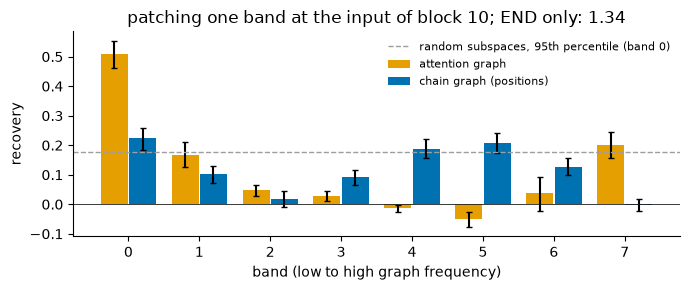

In [14]:
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(K)
for off, basis, color, label in [(-0.2, "clean_attention", "#E69F00", "attention graph"),
                                 (0.2, "path", "#0072B2", "chain graph (positions)")]:
    m = np.array([v[0] for v in rec[basis]])
    err = np.array([[v[0] - v[1], v[2] - v[0]] for v in rec[basis]]).T
    ax.bar(x + off, m, 0.38, yerr=err, color=color, label=label, capsize=2)
ax.axhline(np.percentile(rand, 95), color="#9E9E9E", ls="--", lw=1,
           label="random subspaces, 95th percentile (band 0)")
ax.axhline(0, color="#1A1A1A", lw=0.6)
ax.set(xlabel="band (low to high graph frequency)", ylabel="recovery",
       title=f"patching one band at the input of block {LAYER_P}; END only: {end[0]:.2f}")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

At block 10 the lowest band of the attention graph (2 to 3 modes of a 14- to
20-token prompt) recovers about half of the logit difference, above every
positional band and above random subspaces of the same size, so the method
separates bands that matter from bands that do not. Patching the END position
alone recovers more than the full patch: here the position is the more compact
description of where the answer sits. The use-case page runs all 12 layers,
50 random bases per band size and the corrupt run's basis.

## More

- [Interventions tutorial](https://vcnoel.github.io/spectral-trust/tutorials/interventions/): head ablation, steering vectors, weight-spectrum edits and the full patching API.
- The use-case scripts, with the full head sweeps and every layer: [`examples/use_cases/`](https://github.com/vcnoel/spectral-trust/tree/main/examples/use_cases).